# Clustering: K-Means and Hierarchical

**Input:** `cluster_sample_unlabeled.csv` (features), `cluster_sample_labels.csv` (used only for evaluation)  
**Methods:** k-means (Euclidean distance), hierarchical clustering (cosine distance, average linkage)  
**Evaluation:** silhouette score, agreement with known traffic types (adjusted Rand index)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist

sns.set_style("whitegrid")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True)

SEED = 42

## 1. Load Data

In [2]:
X = pd.read_csv("cluster_sample_unlabeled.csv")
labels = pd.read_csv("cluster_sample_labels.csv")["Label"]

print(f"Features: {X.shape[0]:,} rows x {X.shape[1]} columns")
print(f"Labels:   {len(labels):,} rows (not used to fit any model)")

Features: 11,720 rows x 65 columns
Labels:   11,720 rows (not used to fit any model)


## 2. Transform and Scale

Most flow features are strongly right-skewed (a few very large values). Standardizing alone leaves extreme points that form clusters of a handful of rows. A sign-preserving log transform, `sign(x) * log(1 + |x|)`, is applied first. The sign is kept because three features contain negative values. Features are then standardized to mean 0 and standard deviation 1.

In [3]:
X_log = np.sign(X) * np.log1p(X.abs())

scaler = StandardScaler()
Z = scaler.fit_transform(X_log)

Z_plain = StandardScaler().fit_transform(X)

print(f"Median absolute skewness, raw features:    {X.skew().abs().median():.1f}")
print(f"Median absolute skewness, after log:       {X_log.skew().abs().median():.1f}")
print(f"Largest absolute z-score, scaling only:    {np.abs(Z_plain).max():.1f}")
print(f"Largest absolute z-score, log then scale:  {np.abs(Z).max():.1f}")

Median absolute skewness, raw features:    4.3
Median absolute skewness, after log:       0.9
Largest absolute z-score, scaling only:    105.1
Largest absolute z-score, log then scale:  15.3


## 3. K-Means: Choosing k

K-means is fit for k = 2 to 15. Inertia (within-cluster sum of squares) and the mean silhouette score are compared. The silhouette score ranges from -1 to 1; higher means points are closer to their own cluster than to the nearest other cluster.

In [4]:
K_RANGE = range(2, 16)

rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(Z, km.labels_),
    })

scan = pd.DataFrame(rows).set_index("k")
BEST_K = int(scan["silhouette"].idxmax())

print(f"Highest silhouette: k = {BEST_K} ({scan.loc[BEST_K, 'silhouette']:.3f})")
scan.round(3)

Highest silhouette: k = 15 (0.535)


,inertia,silhouette
k,,
2,504133.325,0.337
3,383307.460,0.379
4,331889.978,0.354
5,301881.203,0.354
6,277337.215,0.392
7,259422.924,0.374
8,229833.413,0.398
9,214291.787,0.435
10,192039.352,0.428


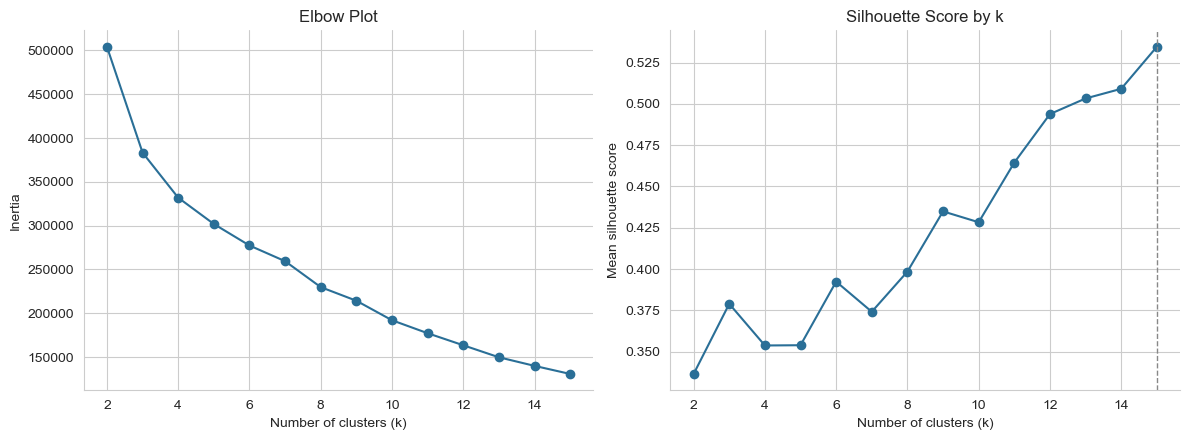

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(scan.index, scan["inertia"], marker="o", color="#2a6f97")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Plot")

axes[1].plot(scan.index, scan["silhouette"], marker="o", color="#2a6f97")
axes[1].axvline(BEST_K, color="#888888", linestyle="--", linewidth=1)
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Mean silhouette score")
axes[1].set_title("Silhouette Score by k")

plt.tight_layout()
plt.savefig("figures/cluster-01-kmeans-k-scan.png", dpi=150)
plt.show()

## 4. K-Means: Cluster Visualization

Clusters are fit on all scaled features. For display only, the data is projected onto its first two principal components. Colors identify cluster membership and carry no other meaning.

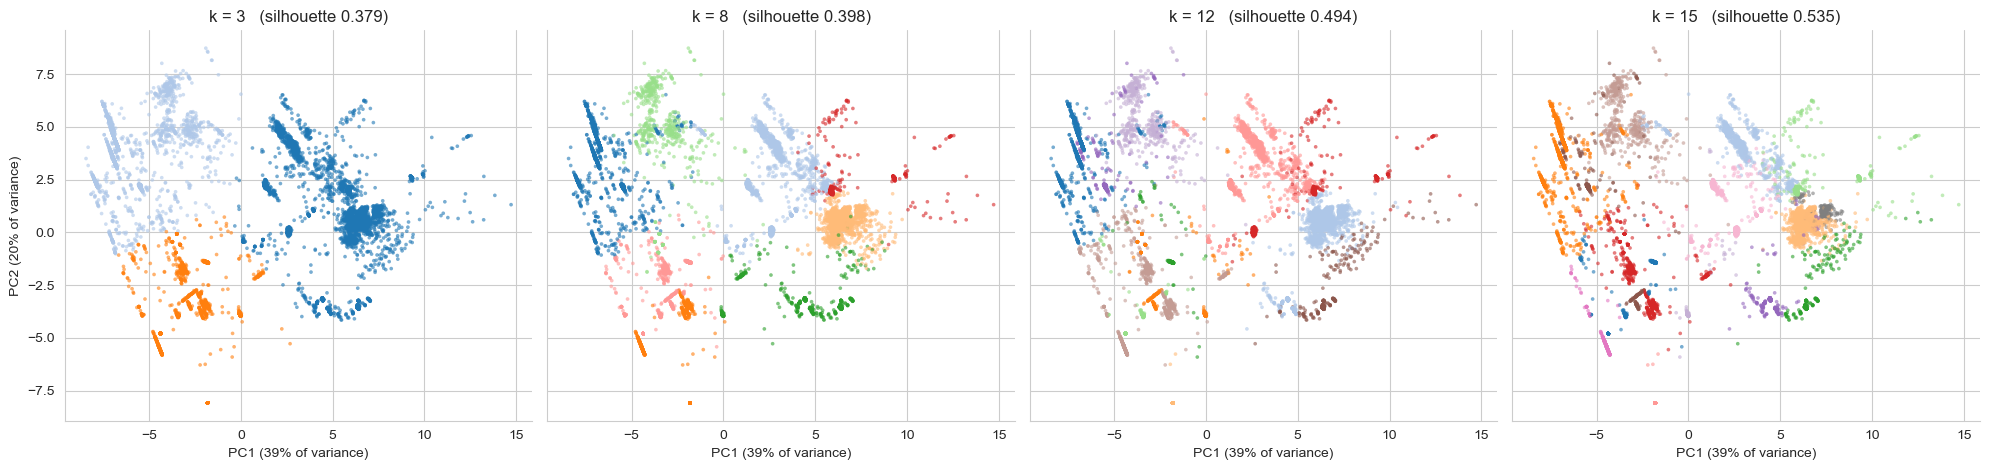

In [6]:
K_SHOW = sorted(set([3, 8, 12, BEST_K]))

pca_view = PCA(n_components=2, random_state=SEED).fit(Z)
Z2 = pca_view.transform(Z)
ev = pca_view.explained_variance_ratio_

fig, axes = plt.subplots(1, len(K_SHOW), figsize=(5 * len(K_SHOW), 4.8), sharex=True, sharey=True)

for ax, k in zip(axes, K_SHOW):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    sns.scatterplot(x=Z2[:, 0], y=Z2[:, 1], hue=km.labels_, palette="tab20",
                    s=7, alpha=0.6, linewidth=0, legend=False, ax=ax)
    ax.set_title(f"k = {k}   (silhouette {scan.loc[k, 'silhouette']:.3f})")
    ax.set_xlabel(f"PC1 ({ev[0]:.0%} of variance)")
    ax.set_ylabel(f"PC2 ({ev[1]:.0%} of variance)")

plt.tight_layout()
plt.savefig("figures/cluster-02-kmeans-clusters.png", dpi=150)
plt.show()

## 5. Silhouette Analysis at the Best k

Each bar is one flow, grouped by cluster. The dashed line is the mean silhouette score. Wide, long bars indicate a compact, well-separated cluster; bars that extend to the left of zero indicate flows that sit closer to another cluster.

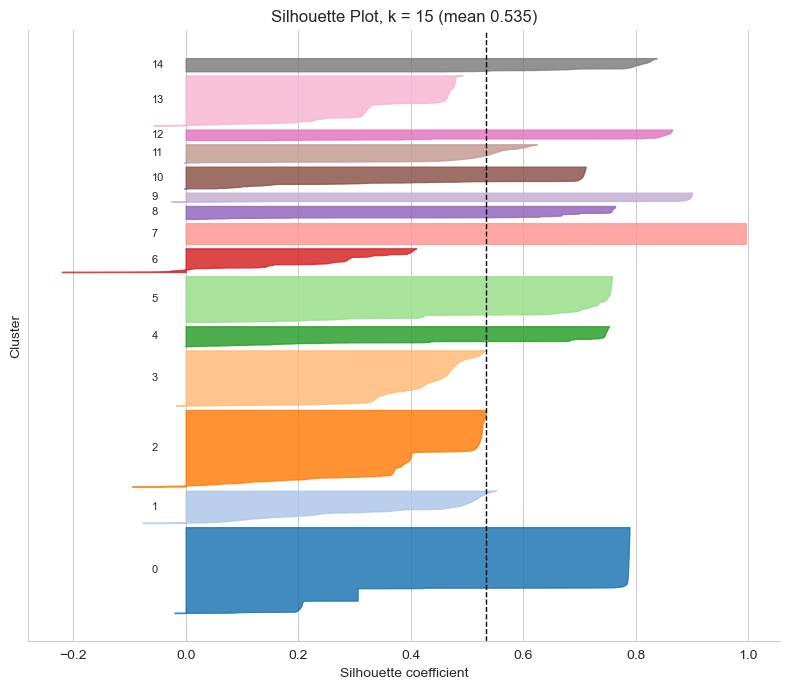

In [7]:
km_best = KMeans(n_clusters=BEST_K, n_init=10, random_state=SEED).fit(Z)
sil = silhouette_samples(Z, km_best.labels_)

fig, ax = plt.subplots(figsize=(8, 7))
cmap = plt.get_cmap("tab20")
y_lower = 10

for i in range(BEST_K):
    vals = np.sort(sil[km_best.labels_ == i])
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, color=cmap(i % 20), alpha=0.85)
    ax.text(-0.06, y_lower + 0.5 * len(vals), str(i), fontsize=8, va="center")
    y_lower = y_upper + 100

ax.axvline(sil.mean(), color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Silhouette coefficient")
ax.set_ylabel("Cluster")
ax.set_yticks([])
ax.set_title(f"Silhouette Plot, k = {BEST_K} (mean {sil.mean():.3f})")

plt.tight_layout()
plt.savefig("figures/cluster-03-silhouette-plot.png", dpi=150)
plt.show()

In [8]:
per_cluster = (
    pd.DataFrame({"cluster": km_best.labels_, "silhouette": sil})
    .groupby("cluster")["silhouette"]
    .agg(size="size", mean_silhouette="mean", share_negative=lambda s: (s < 0).mean())
)
per_cluster.round(3)

,size,mean_silhouette,share_negative
cluster,,,
0,2030,0.629,0.002
1,761,0.373,0.012
2,1809,0.427,0.012
3,1310,0.426,0.003
4,471,0.600,0.002
5,1082,0.666,0.000
6,560,0.240,0.105
7,495,0.992,0.000
8,306,0.638,0.000


## 6. K-Means Clusters Compared with Known Traffic Types

Labels were held out during clustering. Here each traffic type is cross-tabulated with the clusters. Each row shows how a traffic type is spread across clusters. The adjusted Rand index (ARI) measures overall agreement: 0 is chance level, 1 is a perfect match.

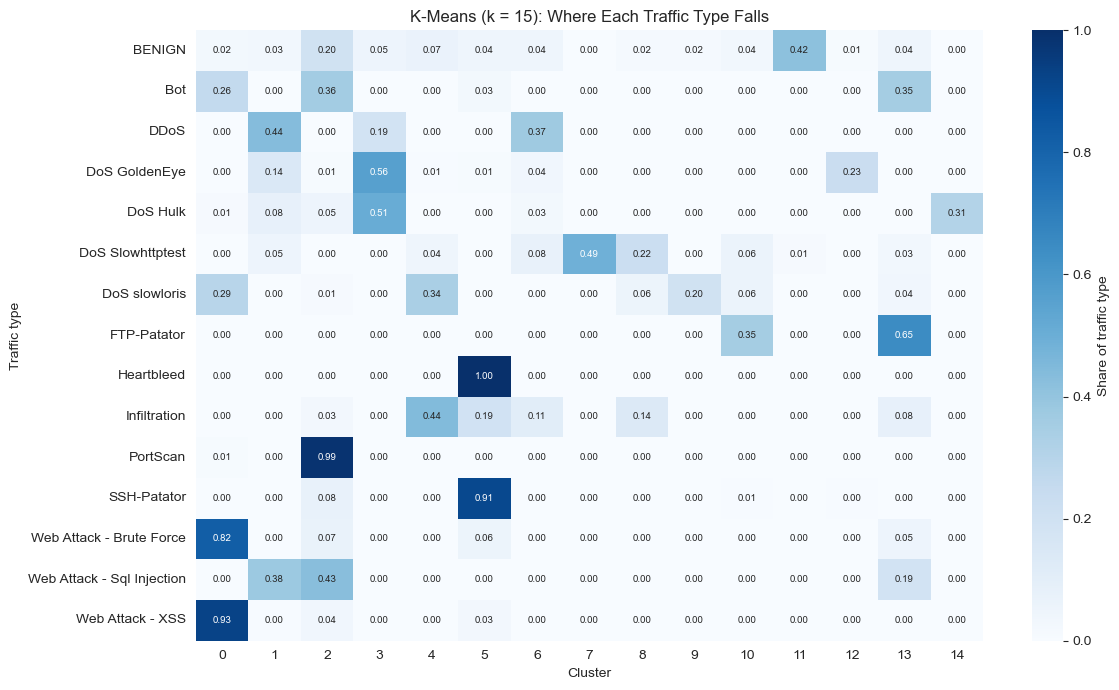

Adjusted Rand index: 0.391
Cluster purity:      0.622


In [9]:
ct = pd.crosstab(labels, km_best.labels_)
ct_share = ct.div(ct.sum(axis=1), axis=0)

plt.figure(figsize=(12, 7))
sns.heatmap(ct_share, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            annot_kws={"size": 7}, cbar_kws={"label": "Share of traffic type"})
plt.xlabel("Cluster")
plt.ylabel("Traffic type")
plt.title(f"K-Means (k = {BEST_K}): Where Each Traffic Type Falls")
plt.tight_layout()
plt.savefig("figures/cluster-04-clusters-vs-labels.png", dpi=150)
plt.show()

ari_km = adjusted_rand_score(labels, km_best.labels_)
purity = ct.max(axis=0).sum() / ct.values.sum()
print(f"Adjusted Rand index: {ari_km:.3f}")
print(f"Cluster purity:      {purity:.3f}")

## 7. Hierarchical Clustering (Cosine Distance)

Hierarchical clustering needs a distance between every pair of rows, which is impractical for all 11,720 flows. A random subsample of 3,000 flows is used.

Cosine distance compares the direction of two feature vectors rather than their length. Average linkage is used because Ward linkage assumes Euclidean distance.

In [10]:
N_SUB = 3000

sub_idx = np.random.RandomState(SEED).choice(len(Z), N_SUB, replace=False)
Z_sub = Z[sub_idx]
labels_sub = labels.iloc[sub_idx].reset_index(drop=True)

dist = pdist(Z_sub, metric="cosine")
link = linkage(dist, method="average")

print(f"Subsample: {N_SUB:,} flows, {len(dist):,} pairwise distances")
print("Heights of the last 8 merges:", np.round(link[-8:, 2], 3))

Subsample: 3,000 flows, 4,498,500 pairwise distances
Heights of the last 8 merges: [0.662 0.705 0.705 0.708 0.846 0.906 0.97  1.357]


### Choosing k for the Hierarchical Result

The tree is cut at each k from 2 to 15 and the cosine silhouette score is computed.

In [11]:
h_rows = []
for k in K_RANGE:
    c = fcluster(link, k, criterion="maxclust")
    h_rows.append({"k": k, "silhouette": silhouette_score(Z_sub, c, metric="cosine")})

h_scan = pd.DataFrame(h_rows).set_index("k")
BEST_K_H = int(h_scan["silhouette"].idxmax())

print(f"Highest cosine silhouette: k = {BEST_K_H} ({h_scan.loc[BEST_K_H, 'silhouette']:.3f})")
h_scan.round(3)

Highest cosine silhouette: k = 3 (0.541)


,silhouette
k,
2,0.525
3,0.541
4,0.458
5,0.457
6,0.453
7,0.491
8,0.475
9,0.474
10,0.441


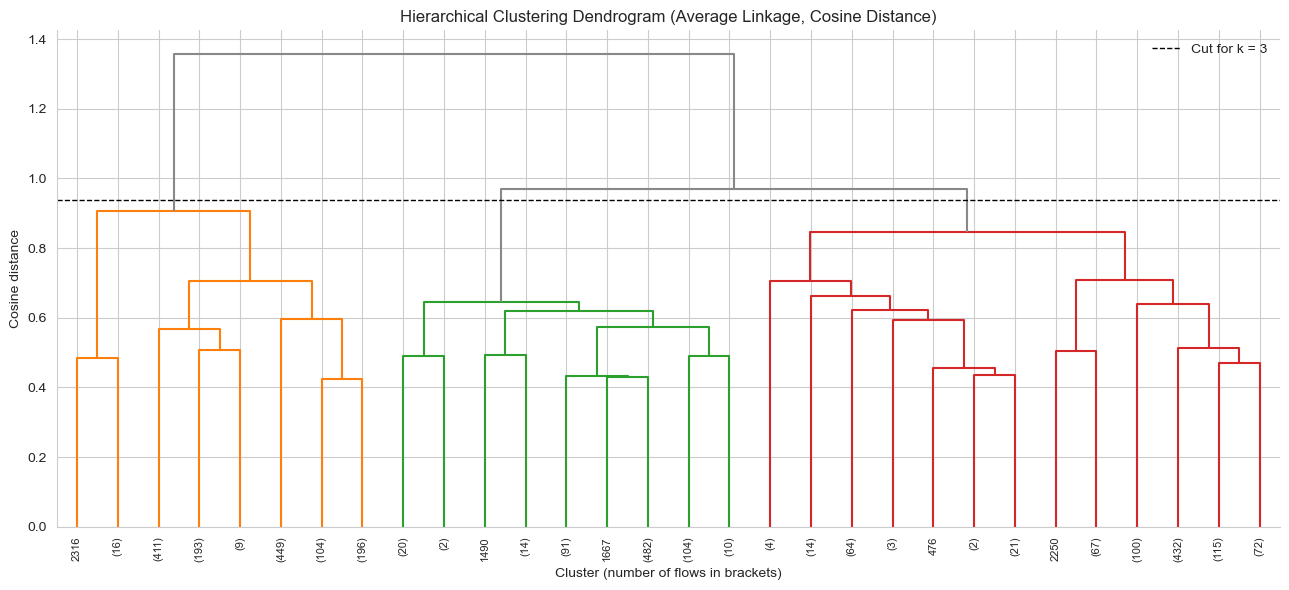

In [12]:
n_merges = len(link)
cut_height = (link[n_merges - BEST_K_H, 2] + link[n_merges - BEST_K_H + 1, 2]) / 2

fig, ax = plt.subplots(figsize=(13, 6))
dendrogram(link, truncate_mode="lastp", p=30, show_leaf_counts=True,
           leaf_rotation=90, leaf_font_size=8, color_threshold=cut_height,
           above_threshold_color="#888888", ax=ax)
ax.axhline(cut_height, color="black", linestyle="--", linewidth=1,
           label=f"Cut for k = {BEST_K_H}")
ax.set_xlabel("Cluster (number of flows in brackets)")
ax.set_ylabel("Cosine distance")
ax.set_title("Hierarchical Clustering Dendrogram (Average Linkage, Cosine Distance)")
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig("figures/cluster-05-dendrogram.png", dpi=150)
plt.show()

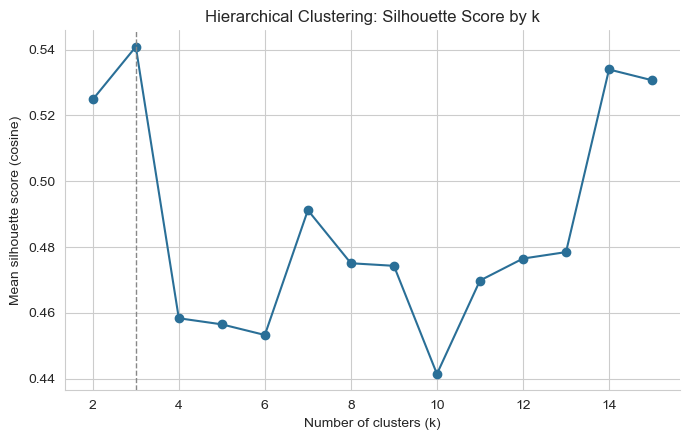

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(h_scan.index, h_scan["silhouette"], marker="o", color="#2a6f97")
ax.axvline(BEST_K_H, color="#888888", linestyle="--", linewidth=1)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Mean silhouette score (cosine)")
ax.set_title("Hierarchical Clustering: Silhouette Score by k")

plt.tight_layout()
plt.savefig("figures/cluster-06-hclust-silhouette.png", dpi=150)
plt.show()

## 8. Comparing Hierarchical Clustering with K-Means

Both methods are scored on the same 3,000-flow subsample using cosine silhouette and agreement with the known traffic types. The k-means labels for the subsample come from the k-means fit on all flows.

In [14]:
def score(name, assigned):
    return {
        "method": name,
        "clusters": len(np.unique(assigned)),
        "cosine silhouette": silhouette_score(Z_sub, assigned, metric="cosine"),
        "ARI vs traffic types": adjusted_rand_score(labels_sub, assigned),
    }

h_best = fcluster(link, BEST_K_H, criterion="maxclust")
h_same = fcluster(link, BEST_K, criterion="maxclust")
km_same = km_best.labels_[sub_idx]
km_h = KMeans(n_clusters=BEST_K_H, n_init=10, random_state=SEED).fit(Z_sub).labels_

comparison = pd.DataFrame([
    score(f"Hierarchical, k = {BEST_K_H} (its best k)", h_best),
    score(f"K-means, k = {BEST_K_H}", km_h),
    score(f"Hierarchical, k = {BEST_K}", h_same),
    score(f"K-means, k = {BEST_K} (its best k)", km_same),
]).set_index("method")

print(f"Agreement between hierarchical and k-means at k = {BEST_K} (ARI): "
      f"{adjusted_rand_score(h_same, km_same):.3f}")
comparison.round(3)

Agreement between hierarchical and k-means at k = 15 (ARI): 0.551


,clusters,cosine silhouette,ARI vs traffic types
method,,,
"Hierarchical, k = 3 (its best k)",3,0.541,0.116
"K-means, k = 3",3,0.543,0.114
"Hierarchical, k = 15",15,0.531,0.282
"K-means, k = 15 (its best k)",15,0.546,0.389


## 9. Summary of Results

In [15]:
print(f"K-means")
print(f"  k values shown:                  {K_SHOW}")
print(f"  Best k by silhouette:            {BEST_K} (mean silhouette {scan.loc[BEST_K, 'silhouette']:.3f})")
print(f"  Agreement with traffic types:    ARI {ari_km:.3f}, purity {purity:.3f}")
print()
print(f"Hierarchical (cosine, average linkage, {N_SUB:,} flows)")
print(f"  Best k by silhouette:            {BEST_K_H} (cosine silhouette {h_scan.loc[BEST_K_H, 'silhouette']:.3f})")
print()
print("Figures saved to figures/: cluster-01 to cluster-06")

K-means
  k values shown:                  [3, 8, 12, 15]
  Best k by silhouette:            15 (mean silhouette 0.535)
  Agreement with traffic types:    ARI 0.391, purity 0.622

Hierarchical (cosine, average linkage, 3,000 flows)
  Best k by silhouette:            3 (cosine silhouette 0.541)

Figures saved to figures/: cluster-01 to cluster-06
